# **TP3 - Architectures CNN classiques et avancées**



## 1. Introduction

Les réseaux de neurones convolutifs (CNN) sont des modèles de Deep Learning utilisés principalement pour l'analyse et la classification des images.

L'objectif de ce TP est d'implémenter et de comparer cinq architectures CNN :
- LeNet
- AlexNet
- VGG
- ResNet
- EfficientNet

## 2. Objectifs

- Comprendre le fonctionnement des architectures CNN.
- Implémenter les modèles avec TensorFlow/Keras.
- Entraîner les modèles sur CIFAR-10.
- Comparer leurs performances et leur coût de calcul.
- Interpréter les courbes d'apprentissage et les résultats obtenus.

## 3. Environnement de travail

- Langage : Python
- Bibliothèque : TensorFlow/Keras
- Dataset : CIFAR-10
- Environnement : Jupyter Notebook


##  Étape 1 : Importation des bibliothèques et graine aléatoire

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# On fixe la graine pour que les résultats soient reproductibles
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Vérifier que le GPU est bien détecté
print("Version TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

Version TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Étape 2 : Chargement de CIFAR-10 via Hugging Face

In [ ]:
from datasets import load_dataset
import numpy as np

# Téléchargement du jeu de données (serveur rapide)
ds = load_dataset("uoft-cs/cifar10")

# Conversion des images en tableaux numpy (x = images, y = étiquettes)
x_train = np.array([np.array(img) for img in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"])
x_test = np.array([np.array(img) for img in ds["test"]["img"]])
y_test = np.array(ds["test"]["label"])

# Noms des 10 classes
class_names = ['avion', 'automobile', 'oiseau', 'chat', 'cerf',
               'chien', 'grenouille', 'cheval', 'bateau', 'camion']

# Affichage des formes (réponse à la question 1)
print("Classes :", class_names)
print("x_train :", x_train.shape)
print("y_train :", y_train.shape)
print("x_test  :", x_test.shape)
print("y_test  :", y_test.shape)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Classes : ['avion', 'automobile', 'oiseau', 'chat', 'cerf', 'chien', 'grenouille', 'cheval', 'bateau', 'camion']
x_train : (50000, 32, 32, 3)
y_train : (50000,)
x_test  : (10000, 32, 32, 3)
y_test  : (10000,)


## Partie A – Étapes 3 à 5 : Normalisation, validation et lots

In [ ]:
# Étape 3 : normalisation des pixels entre 0 et 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Valeurs des pixels : min =", x_train.min(), ", max =", x_train.max())

# Étape 4 : création d'un jeu de validation fixe (5000 images)
VAL_SIZE = 5000

# Mélange des indices avec une graine fixe : le découpage est toujours le même
rng = np.random.RandomState(SEED)
indices = rng.permutation(len(x_train))

val_idx = indices[:VAL_SIZE]      # 5000 images pour la validation
train_idx = indices[VAL_SIZE:]    # le reste pour l'entraînement

x_val, y_val = x_train[val_idx], y_train[val_idx]
x_train, y_train = x_train[train_idx], y_train[train_idx]

# Nombre d'images par sous-ensemble (réponse à la question 4)
print("Entraînement :", len(x_train), "images")
print("Validation   :", len(x_val), "images")
print("Test         :", len(x_test), "images")

# Étape 5 : création des datasets tf.data par lots de 64 images
BATCH_SIZE = 64

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)) \
    .shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)) \
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)) \
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Datasets prêts, taille d'un lot :", BATCH_SIZE)

Valeurs des pixels : min = 0.0 , max = 1.0
Entraînement : 45000 images
Validation   : 5000 images
Test         : 10000 images
Datasets prêts, taille d'un lot : 64



### Question 1 — Forme de x_train

La forme de `x_train` est `(50000, 32, 32, 3)`.

- 50000 : nombre d'images d'entraînement.
- 32 : hauteur de chaque image en pixels.
- 32 : largeur de chaque image en pixels.
- 3 : nombre de canaux de couleur RGB (rouge, vert et bleu).

Chaque image est donc représentée par un tableau de pixels de dimensions 32 × 32 × 3.



### Question 2 — Différence entre validation et test

Le jeu de validation sert à suivre les performances du modèle pendant l'entraînement, à choisir les hyperparamètres et à appliquer l'arrêt anticipé (*Early Stopping*).

Le jeu de test est réservé à l'évaluation finale du modèle sur des données qui n'ont pas été utilisées pour ajuster ses paramètres ou choisir ses hyperparamètres.

Cette séparation permet d'obtenir une évaluation plus fiable de la capacité de généralisation du modèle.



### Question 3 — Augmentation des données

Deux augmentations adaptées à CIFAR-10 sont :

1. `RandomFlip("horizontal")` : retourne aléatoirement les images horizontalement afin d'améliorer la robustesse du modèle.
2. `RandomTranslation(0.1, 0.1)` : déplace légèrement les images horizontalement et verticalement pour réduire la dépendance à la position exacte des objets.

Une augmentation à éviter est le retournement vertical systématique ou aléatoire, car il peut produire des images peu naturelles pour certaines classes.

Les augmentations doivent être appliquées uniquement aux données d'entraînement, et de manière identique pour toutes les architectures comparées.



### Question 4 — Nombre d'images par sous-ensemble

Le dataset CIFAR-10 contient initialement 50 000 images d'entraînement et 10 000 images de test.

Nous réservons 5 000 images du jeu d'entraînement initial pour la validation.

Le découpage final est donc :
- Entraînement : 50 000 − 5 000 = 45 000 images.
- Validation : 5 000 images.
- Test : 10 000 images.

Le nombre total d'images reste égal à 60 000.



### Protocole expérimental

| Élément | Valeur choisie | Justification |
|---|---|---|
| Taille validation | 5 000 images (10 %) | Évaluer la généralisation pendant l'entraînement. |
| Batch size | 64 | Compromis entre mémoire et vitesse de calcul. |
| Nombre maximal d'époques | 30 | Utiliser le même budget maximal pour chaque architecture. |
| Patience | 5 | Arrêter l'entraînement si la validation ne s'améliore plus pendant 5 époques. |

Les mêmes paramètres expérimentaux seront utilisés pour toutes les architectures afin de rendre la comparaison aussi équitable que possible.



# Partie B — Architectures CNN

##  LeNet-5 : poser une ligne de base
LeNet-5 est une architecture classique de réseau de neurones convolutif (CNN).

Dans ce TP, nous allons construire une version adaptée au dataset CIFAR-10.

L'architecture comprend :
- Des couches de convolution pour extraire les caractéristiques des images.
- Des couches de pooling pour réduire les dimensions spatiales.
- Une couche Flatten pour transformer les cartes de caractéristiques en vecteur.
- Des couches Dense pour réaliser la classification.
- Une couche de sortie Softmax pour prédire l'une des 10 classes de CIFAR-10.

L'objectif est d'obtenir un modèle de référence simple avant de comparer des architectures plus avancées.


## 1. Implémenter LeNet

In [ ]:
# Construction de LeNet adapté à CIFAR-10 (2 blocs convolution + pooling)
def build_lenet(input_shape=(32, 32, 3), n_classes=10):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(6, kernel_size=5, activation="relu"),    # bloc 1 : 6 filtres 5x5
        layers.AveragePooling2D(pool_size=2),                  # réduit la taille par 2
        layers.Conv2D(16, kernel_size=5, activation="relu"),   # bloc 2 : 16 filtres 5x5
        layers.AveragePooling2D(pool_size=2),
        layers.Flatten(),                                      # met les cartes à plat
        layers.Dense(120, activation="relu"),                  # couches denses
        layers.Dense(84, activation="relu"),
        layers.Dense(n_classes, activation="softmax")          # 10 classes
    ], name="LeNet_adapte")
    return model

lenet = build_lenet()
lenet.summary()

# Vérification : un lot d'images traverse bien le modèle
lot_images, _ = next(iter(train_ds))
print("Sortie pour un lot :", lenet(lot_images).shape)   # attendu : (64, 10)

Model: "LeNet_adapte"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

Sortie pour un lot : (64, 10)



### Tableau — Formes de sortie et paramètres calculés

| Couche | Sortie attendue | Paramètres calculés |
|---|---|---:|
| Conv 1 | 32 × 32 × 32 | 896 |
| Pooling 1 | 16 × 16 × 32 | 0 |
| Conv 2 | 16 × 16 × 64 | 18 496 |
| Classifieur (Dense 120, Dense 84, Softmax 10) | 10 classes | 502 654 |




### Questions d'analyse — LeNet-5

**1. Quel effet produit le pooling sur la résolution et le champ réceptif ?**

Le pooling réduit la résolution spatiale des cartes de caractéristiques. Il permet de diminuer le coût de calcul et d'augmenter progressivement le champ réceptif relatif des neurones. Cependant, une partie des informations spatiales peut être perdue.

**2. Pourquoi cette architecture constitue-t-elle une bonne baseline ?**

LeNet constitue une bonne baseline grâce à sa structure simple, à son nombre limité de couches et à son coût de calcul relativement faible. Elle permet d'obtenir un premier résultat de référence avant de comparer des architectures plus complexes.

**3. Comparer AveragePooling et MaxPooling dans ce contexte.**

MaxPooling conserve la valeur maximale de chaque région et peut mettre en évidence les caractéristiques les plus fortes. AveragePooling calcule la moyenne des valeurs de chaque région et conserve une information plus globale. Le meilleur choix dépend des résultats expérimentaux obtenus.



## 2. AlexNet-small : profondeur, ReLU et régularisation

AlexNet est une architecture CNN qui utilise plusieurs couches convolutives, la fonction d'activation ReLU et des techniques de régularisation.

Dans ce TP, nous construisons une version simplifiée adaptée aux images CIFAR-10 de taille 32 × 32.

Les principaux éléments sont :
- Plusieurs couches de convolution pour extraire des caractéristiques.
- ReLU pour introduire la non-linéarité.
- Batch Normalization pour stabiliser l'apprentissage.
- MaxPooling pour réduire les dimensions spatiales.
- Dropout pour limiter le surapprentissage.
- Softmax pour classer les images en 10 catégories.


In [ ]:
# Construction d'AlexNet réduit : convolutions profondes, ReLU, BatchNorm, Dropout
def build_alexnet_small(input_shape=(32, 32, 3), n_classes=10):
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv2D(64, 3, padding="same")(inputs)      # bloc 1 : 64 filtres
    x = layers.ReLU()(x)
    x = layers.BatchNormalization()(x)                    # normalisation
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)   # bloc 2
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(192, 3, padding="same", activation="relu")(x)   # 3 convolutions
    x = layers.Conv2D(192, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)           # classifieur compact
    x = layers.Dropout(0.5)(x)                            # dropout : évite le surapprentissage
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="AlexNet_small")

alexnet = build_alexnet_small()
alexnet.summary()

Model: "AlexNet_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 192)      │       221,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 192)      │       331,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,186 (5.26 MB)

 Trainable params: 1,377,802 (5.26 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
for images, labels in train_ds.take(1):
    predictions = model_alexnet(images)

    print("Images :", images.shape)
    print("Labels :", labels.shape)
    print("Prédictions :", predictions.shape)


### Questions d'analyse — AlexNet-small

**1. Pourquoi ReLU accélère-t-elle généralement l'optimisation par rapport à sigmoid ?**

ReLU est simple à calculer et réduit le risque de gradients très faibles pour les activations positives. Elle peut donc faciliter l'apprentissage des réseaux profonds.

**2. Quel symptôme indiquerait un dropout trop fort ?**

Un dropout trop fort peut entraîner un sous-apprentissage : la précision d'entraînement reste faible et la perte d'entraînement ne diminue pas suffisamment.

**3. La couche Dense domine-t-elle le nombre de paramètres ?**

Cette question doit être vérifiée avec `model.summary()`. Dans notre architecture, Flatten produit un vecteur de grande dimension, ce qui peut rendre la première couche Dense particulièrement coûteuse en paramètres.

**4. Comment réduire les paramètres sans supprimer la profondeur ?**

On peut remplacer Flatten par GlobalAveragePooling2D avant la couche de classification, puis comparer le nombre de paramètres et les performances.



## 3. VGG-small : empiler des convolutions 3 × 3

VGG repose sur l'empilement de plusieurs couches convolutives de petite taille, généralement 3 × 3.

Dans cette version adaptée à CIFAR-10, l'architecture comprend trois blocs :
- Bloc 1 : deux convolutions avec 32 filtres, suivies d'un MaxPooling.
- Bloc 2 : deux convolutions avec 64 filtres, suivies d'un MaxPooling.
- Bloc 3 : trois convolutions avec 128 filtres.

Après l'extraction des caractéristiques, nous comparons deux têtes de classification : Flatten et GlobalAveragePooling2D (GAP).

L'objectif est d'étudier leur influence sur le nombre de paramètres, la précision de validation et le surapprentissage.


In [ ]:
# Bloc VGG : plusieurs convolutions 3x3 puis un pooling
def vgg_block(x, filters, n_conv):
    for _ in range(n_conv):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return layers.MaxPooling2D()(x)

# Construction de VGG réduit ; "tete" choisit Flatten ou GlobalAveragePooling
def build_vgg_small(input_shape=(32, 32, 3), n_classes=10, tete="gap"):
    inputs = keras.Input(shape=input_shape)
    x = vgg_block(inputs, 32, 2)
    x = vgg_block(x, 64, 2)
    x = vgg_block(x, 128, 3)
    if tete == "flatten":
        x = layers.Flatten()(x)                  # variante A
    else:
        x = layers.GlobalAveragePooling2D()(x)   # variante B
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"VGG_small_{tete}")

vgg_flatten = build_vgg_small(tete="flatten")
vgg_gap = build_vgg_small(tete="gap")
print("Paramètres VGG Flatten :", vgg_flatten.count_params())
print("Paramètres VGG GAP     :", vgg_gap.count_params())
vgg_gap.summary()

Paramètres VGG Flatten : 455082
Paramètres VGG GAP     : 435882


Model: "VGG_small_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 435,882 (1.66 MB)

 Trainable params: 435,882 (1.66 MB)

 Non-trainable params: 0 (0.00 B)

## Vérifier la propagation d'un batch

In [ ]:

for images, labels in train_ds.take(1):

    pred_flatten = model_vgg_flatten(images)
    pred_gap = model_vgg_gap(images)

    print("Images :", images.shape)
    print("Labels :", labels.shape)
    print("Sortie Flatten :", pred_flatten.shape)
    print("Sortie GAP :", pred_gap.shape)


### Expérience ciblée — Comparaison Flatten et GAP

Les deux variantes utilisent les mêmes blocs convolutifs. Seule la tête de classification change.

| Mesure | Variante A : Flatten | Variante B : GAP |
|---|---|---|
| Paramètres totaux | À relever dans `model.summary()` | À relever dans `model.summary()` |
| Validation accuracy | À mesurer après entraînement | À mesurer après entraînement |
| Écart train-validation | À calculer après entraînement | À calculer après entraînement |

L'écart train-validation est calculé à partir des accuracies :

Écart = Accuracy train − Accuracy validation

Un écart important peut indiquer un surapprentissage. Le choix final doit prendre en compte la précision de validation et le coût en paramètres.



### Questions d'analyse — VGG-small

**1. Pourquoi deux convolutions 3 × 3 peuvent-elles remplacer une convolution plus large ?**

L'empilement de deux convolutions 3 × 3 permet d'obtenir un champ réceptif comparable à celui d'une convolution 5 × 5, tout en utilisant généralement moins de paramètres à nombre de canaux comparable. L'ajout d'activations ReLU entre les couches permet également d'introduire davantage de non-linéarités.

**2. Quel est l'avantage d'une structure en blocs répétitifs ?**

Une structure en blocs facilite la conception, la compréhension et la réutilisation de l'architecture. Elle permet d'extraire progressivement des caractéristiques plus complexes et de réduire les dimensions spatiales à l'aide du pooling.

**3. Quelle tête choisissez-vous pour la suite et sur quelle mesure vous appuyez-vous ?**

Le choix entre Flatten et GlobalAveragePooling2D doit être effectué après l'entraînement des deux variantes. Nous comparerons le nombre total de paramètres, la précision de validation et l'écart entre les accuracies d'entraînement et de validation. La variante retenue sera celle qui offre un compromis satisfaisant entre performance, généralisation et coût de calcul.



## 4. ResNet : apprendre une correction résiduelle

ResNet (Residual Network) utilise des connexions raccourcies, appelées *skip connections*.

Un bloc résiduel apprend une fonction F(x), puis l'ajoute à l'entrée x :

y = ReLU(F(x) + x)

Cette addition permet de conserver un chemin direct pour l'information et facilite généralement la propagation du gradient dans les réseaux profonds.

Pour que l'addition soit possible, les deux tenseurs doivent avoir des dimensions compatibles. Une projection 1 × 1 est utilisée lorsque le nombre de canaux ou la résolution doit être adapté.


In [ ]:
# Bloc résiduel : sortie = ReLU(F(x) + x)
def residual_block(x, filters, stride=1):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.ReLU()(y)
    # seconde convolution + normalisation
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    # si les formes changent, on adapte le raccourci avec une convolution 1x1
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(x)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([y, shortcut])
    return layers.ReLU()(y)

# Construction de ResNet réduit
def build_resnet_small(input_shape=(32, 32, 3), n_classes=10):
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="ResNet_small")

# Test obligatoire avec des tenseurs factices
t1 = tf.random.normal((4, 32, 32, 32))
print("Cas 1 (stride 1, mêmes canaux)  :", residual_block(t1, 32, stride=1).shape)
print("Cas 2 (stride 2)                :", residual_block(t1, 32, stride=2).shape)
t2 = tf.random.normal((4, 16, 16, 32))
print("Cas 3 (canaux 32 -> 64)         :", residual_block(t2, 64, stride=1).shape)

resnet = build_resnet_small()
resnet.summary()

Cas 1 (stride 1, mêmes canaux)  : (4, 32, 32, 32)
Cas 2 (stride 2)                : (4, 16, 16, 32)
Cas 3 (canaux 32 -> 64)         : (4, 16, 16, 64)


Model: "ResNet_small"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_29[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_7 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 32, 32,    │      9,216 │ re_lu_7[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_30[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_8 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 32, 32,    │      9,216 │ re_lu_8[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_31[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 32, 32,    │          0 │ add_3[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 16, 16,    │     18,432 │ re_lu_9[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 16, 16,    │     36,864 │ re_lu_10[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 16, 16,    │      2,048 │ re_lu_9[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_33[0][0] 

 Total params: 309,994 (1.18 MB)

 Trainable params: 308,650 (1.18 MB)

 Non-trainable params: 1,344 (5.25 KB)

#### vérifier les formes

In [ ]:
# Cas 1 : même résolution et même nombre de canaux
x1 = tf.random.normal((2, 32, 32, 32))
y1 = residual_block(x1, filters=32, stride=1)

# Cas 2 : sous-échantillonnage avec stride=2
x2 = tf.random.normal((2, 32, 32, 32))
y2 = residual_block(x2, filters=64, stride=2)

# Cas 3 : même résolution, mais canaux différents
x3 = tf.random.normal((2, 16, 16, 32))
y3 = residual_block(x3, filters=64, stride=1)

print("Cas 1 - Entrée :", x1.shape, "| Sortie :", y1.shape)
print("Cas 2 - Entrée :", x2.shape, "| Sortie :", y2.shape)
print("Cas 3 - Entrée :", x3.shape, "| Sortie :", y3.shape)


### Formes du bloc résiduel

| Cas | Forme de x | Forme de F(x) | Projection requise ? |
|---|---|---|---|
| Même résolution | (B, 32, 32, 32) | (B, 32, 32, 32) | Non |
| Sous-échantillonnage | (B, 32, 32, 32) | (B, 16, 16, 64) | Oui |
| Canaux différents | (B, 16, 16, 32) | (B, 16, 16, 64) | Oui |

**Interprétation :**

Dans le premier cas, l'entrée et la branche résiduelle ont les mêmes dimensions. Le raccourci peut donc être utilisé directement.

Dans les deuxième et troisième cas, les dimensions diffèrent. Une convolution de projection 1 × 1 adapte le raccourci afin de permettre l'addition.



### Questions d'analyse — ResNet

**1. Pourquoi une addition exige-t-elle des formes compatibles ?**

L'addition élément par élément exige que les deux tenseurs possèdent les mêmes dimensions. Si leurs formes diffèrent, l'opération `Add()` ne peut pas réaliser directement l'addition résiduelle.

**2. Comment les raccourcis facilitent-ils la propagation du gradient ?**

Les skip connections offrent un chemin direct à l'information et au gradient. Elles facilitent généralement l'optimisation des réseaux profonds et atténuent le problème de disparition du gradient.

**3. Comparer un bloc résiduel à un bloc VGG de profondeur similaire.**

Un bloc VGG empile des convolutions successives sans addition directe avec l'entrée. Un bloc ResNet ajoute une connexion raccourcie qui permet de combiner l'entrée et les caractéristiques transformées. Cette structure peut faciliter l'entraînement de réseaux plus profonds.

**4. Que se passe-t-il si la projection 1 × 1 est oubliée lors d'un changement de canaux ?**

Si le nombre de canaux ou la résolution diffère entre l'entrée et la branche résiduelle, les tenseurs ne sont généralement plus compatibles. L'opération `Add()` provoque alors une erreur de dimensions.



## 9. EfficientNetB0 : équilibrer profondeur, largeur et résolution

EfficientNet utilise une stratégie de mise à l'échelle composée (*compound scaling*), qui équilibre la profondeur du réseau, sa largeur et la résolution des images.

Ses blocs MBConv utilisent notamment :
- Une convolution 1 × 1 pour l'expansion des canaux.
- Une convolution depthwise pour extraire les caractéristiques spatiales à moindre coût.
- Un mécanisme Squeeze-and-Excitation pour ajuster l'importance des canaux.
- Une projection 1 × 1 pour réduire le nombre de canaux.
- Une connexion résiduelle lorsque les dimensions le permettent.

Dans ce TP, nous utilisons EfficientNetB0 sans poids préentraînés (`weights=None`) afin de comparer son apprentissage à partir de zéro avec celui des autres architectures.


In [ ]:
# EfficientNetB0 entraîné depuis zéro (weights=None) pour la comparaison
def build_efficientnet(input_shape=(32, 32, 3), n_classes=10):
    inputs = keras.Input(shape=input_shape)
    base = keras.applications.EfficientNetB0(
        include_top=False, weights=None, input_tensor=inputs
    )
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="EfficientNetB0")

effnet = build_efficientnet()
print("Paramètres totaux :", effnet.count_params())
# Repérer un bloc MBConv dans le modèle
print([c.name for c in effnet.layers if "block2a" in c.name])

Paramètres totaux : 4062381
['block2a_expand_conv', 'block2a_expand_bn', 'block2a_expand_activation', 'block2a_dwconv_pad', 'block2a_dwconv', 'block2a_bn', 'block2a_activation', 'block2a_se_squeeze', 'block2a_se_reshape', 'block2a_se_reduce', 'block2a_se_expand', 'block2a_se_excite', 'block2a_project_conv', 'block2a_project_bn']



### Questions d'analyse — EfficientNetB0

**1. Pourquoi le scaling composé est-il plus cohérent que l'augmentation d'une seule dimension ?**

Le scaling composé équilibre la profondeur, la largeur et la résolution des images. Augmenter une seule dimension peut entraîner un coût de calcul important sans garantir une amélioration proportionnelle des performances. Le scaling composé cherche un meilleur compromis entre capacité du modèle et ressources utilisées.

**2. Quel rôle joue la convolution depthwise ?**

La convolution depthwise applique un filtre spatial indépendamment sur chaque canal d'entrée. Elle réduit le coût de calcul par rapport à une convolution standard, puis une convolution 1 × 1 permet de combiner les informations entre les canaux.

**3. Comparer les paramètres et le temps d'entraînement à VGG-small.**

Le nombre de paramètres doit être relevé dans `model.summary()`. Le temps d'entraînement sera mesuré avec le même protocole, le même nombre de données et les mêmes conditions matérielles. La comparaison permettra d'étudier le compromis entre complexité, temps d'exécution et précision de validation.



### Discussion — Limites de la résolution

EfficientNetB0 a été conçue pour traiter des images de résolution plus élevée que celles de CIFAR-10 (32 × 32 pixels).

L'utilisation de cette architecture sur CIFAR-10 peut modifier son comportement et limiter l'intérêt de certaines caractéristiques de sa conception initiale. Les résultats doivent donc être interprétés avec prudence.

La comparaison doit prendre en compte non seulement l'accuracy, mais aussi le nombre de paramètres et le temps d'entraînement.



# Partie C — Entraînement et comparaison des architectures CNN

L'objectif est d'entraîner et de comparer cinq architectures : LeNet, AlexNet-small, VGG-small, ResNet et EfficientNetB0.

Toutes les architectures utilisent le même jeu d'entraînement, le même jeu de validation, le même jeu de test et une procédure d'optimisation comparable.

Les mesures étudiées sont le nombre de paramètres, la précision de validation, la précision de test, le temps d'entraînement et la latence d'inférence.



# Partie C — Entraînement et comparaison des architectures CNN

L'objectif est d'entraîner et de comparer cinq architectures : LeNet, AlexNet-small, VGG-small, ResNet et EfficientNetB0.

Toutes les architectures utilisent le même jeu d'entraînement, le même jeu de validation, le même jeu de test et une procédure d'optimisation comparable.

Les mesures étudiées sont le nombre de paramètres, la précision de validation, la précision de test, le temps d'entraînement et la latence d'inférence.



## 1. Protocole d'entraînement

Nous utilisons l'optimiseur Adam avec un taux d'apprentissage initial de 0,001.

La fonction de perte est sparse_categorical_crossentropy, adaptée aux étiquettes entières de CIFAR-10.

EarlyStopping surveille la perte de validation et arrête l'entraînement lorsqu'aucune amélioration n'est observée pendant plusieurs époques. ReduceLROnPlateau diminue le taux d'apprentissage lorsque la perte de validation cesse de s'améliorer.


### A. Fonction d'entraînement

In [ ]:
# Paramètres communs d'entraînement pour tous les modèles
EPOCHS = 30      # nombre maximal d'époques
PATIENCE = 5     # patience de l'arrêt anticipé

def compile_and_train(model, train_ds, val_ds, epochs=EPOCHS):
    # Compilation : optimiseur Adam, perte adaptée à des étiquettes entières
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    callbacks = [
        # Arrêt si la perte de validation ne s'améliore plus, on garde les meilleurs poids
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True),
        # Réduit le pas d'apprentissage quand la validation stagne
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    ]
    return model.fit(train_ds, validation_data=val_ds,
                     epochs=epochs, callbacks=callbacks, verbose=2)

## B. Fonctions de mesure

In [ ]:
import time

def mesurer_latence(model, images, n=100):
    # Temps moyen de prédiction pour une image (moyenne sur 100 images, en ms)
    model(images[:1], training=False)          # échauffement
    debut = time.time()
    for i in range(n):
        model(images[i:i+1], training=False)
    return (time.time() - debut) / n * 1000

## C. Entraînement des modèles

In [ ]:
# Les 6 modèles à comparer (VGG avec ses 2 variantes)
model_builders = {
    "LeNet": build_lenet,
    "AlexNet-small": build_alexnet_small,
    "VGG-small (GAP)": lambda: build_vgg_small(tete="gap"),
    "VGG-small (Flatten)": lambda: build_vgg_small(tete="flatten"),
    "ResNet-small": build_resnet_small,
    "EfficientNetB0": build_efficientnet,
}

results = []      # une ligne de résultats par modèle
histories = {}    # courbes d'apprentissage, pour la Partie D

for name, builder in model_builders.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)       # même graine pour chaque modèle
    model = builder()

    # Entraînement chronométré
    debut = time.time()
    history = compile_and_train(model, train_ds, val_ds)
    duree = time.time() - debut
    n_ep = len(history.history["loss"])

    # Évaluation avec les meilleurs poids restaurés
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # Écart train-val à la meilleure époque
    best = int(np.argmin(history.history["val_loss"]))
    ecart = history.history["accuracy"][best] - history.history["val_accuracy"][best]

    results.append({
        "model": name,
        "params": model.count_params(),
        "epochs": n_ep,
        "seconds": round(duree, 1),
        "sec_per_epoch": round(duree / n_ep, 1),
        "val_acc": round(100 * val_acc, 2),
        "test_acc": round(100 * test_acc, 2),
        "test_loss": round(test_loss, 3),
        "gap_train_val": round(100 * ecart, 2),
        "latency_ms": round(mesurer_latence(model, x_test), 2),
    })
    histories[name] = history.history
    print(">>>", name, "terminé en", round(duree), "s\n")

Epoch 1/30
704/704 - 14s - 19ms/step - accuracy: 0.3853 - loss: 1.6811 - val_accuracy: 0.4696 - val_loss: 1.4692 - learning_rate: 0.0010
Epoch 2/30
704/704 - 2s - 3ms/step - accuracy: 0.4907 - loss: 1.4075 - val_accuracy: 0.5026 - val_loss: 1.3538 - learning_rate: 0.0010
Epoch 3/30
704/704 - 3s - 4ms/step - accuracy: 0.5298 - loss: 1.3132 - val_accuracy: 0.5282 - val_loss: 1.3132 - learning_rate: 0.0010
Epoch 4/30
704/704 - 3s - 4ms/step - accuracy: 0.5592 - loss: 1.2331 - val_accuracy: 0.5582 - val_loss: 1.2378 - learning_rate: 0.0010
Epoch 5/30
704/704 - 2s - 3ms/step - accuracy: 0.5796 - loss: 1.1842 - val_accuracy: 0.5666 - val_loss: 1.2198 - learning_rate: 0.0010
Epoch 6/30
704/704 - 2s - 3ms/step - accuracy: 0.5962 - loss: 1.1382 - val_accuracy: 0.5850 - val_loss: 1.1766 - learning_rate: 0.0010
Epoch 7/30
704/704 - 2s - 3ms/step - accuracy: 0.6112 - loss: 1.0988 - val_accuracy: 0.5860 - val_loss: 1.1791 - learning_rate: 0.0010
Epoch 8/30
704/704 - 2s - 3ms/step - accuracy: 0.6256

## D. Tableau comparatif

In [ ]:
# Tableau comparatif des résultats
tableau = pd.DataFrame(results)
tableau.to_csv("resultats_tp3.csv", index=False)
tableau

,model,params,epochs,seconds,sec_per_epoch,val_acc,test_acc,test_loss,gap_train_val,latency_ms
0,LeNet,62006,19,58.4,3.1,61.78,62.80,1.089,7.70,8.55
1,AlexNet-small,1378186,11,92.8,8.4,77.78,77.43,0.756,8.41,16.26
2,VGG-small (GAP),435882,13,96.6,7.4,77.78,78.43,0.640,3.98,15.32
3,VGG-small (Flatten),455082,11,76.4,6.9,76.22,76.34,0.715,3.89,14.56
4,ResNet-small,309994,17,172.0,10.1,80.06,80.13,0.665,16.50,28.32
5,EfficientNetB0,4062381,24,449.2,18.7,69.36,68.56,0.973,11.06,385.15


### Analyse du tableau comparatif des résultats

Ce tableau présente une comparaison entre six architectures CNN : LeNet, AlexNet-small, VGG-small (GAP), VGG-small (Flatten), ResNet-small et EfficientNetB0.

La comparaison est basée sur plusieurs critères : le nombre de paramètres, le temps d'entraînement, la précision sur les données de validation et de test, la perte (*test loss*), l'écart entre l'entraînement et la validation (*gap train-val*) ainsi que la latence de prédiction.

**Observations :**

- **LeNet** possède le plus petit nombre de paramètres (62 006) et un temps d'entraînement court (58,4 secondes). Cependant, sa précision sur les données de test est de 62,80 %.
- **AlexNet-small** obtient une précision de test de 77,43 %, avec un temps d'entraînement de 92,8 secondes.
- **VGG-small (GAP)** atteint une précision de test de 78,43 % et présente une perte de test de 0,640.
- **VGG-small (Flatten)** obtient une précision de test de 76,34 %. Dans cette expérience, la version GAP donne donc de meilleurs résultats.
- **ResNet-small** obtient la meilleure précision de test, avec 80,13 %. Il présente également une précision de validation de 80,06 %.
- **EfficientNetB0** atteint une précision de test de 68,56 %. Son temps d'entraînement est le plus élevé (449,2 secondes) et sa latence est également la plus importante (385,15 ms par image).



## E. Contrôle d'équité
Cette étape permet de vérifier les conditions utilisées pendant les expériences afin de rendre la comparaison entre les architectures plus cohérente et reproductible.


In [ ]:
# Contrôle d'équité : versions, graine et réglages communs
import sys
print("Python      :", sys.version.split()[0])
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("NumPy       :", np.__version__)
print("GPU         :", tf.config.list_physical_devices("GPU"))
print("Graine :", SEED, "| Batch :", BATCH_SIZE,
      "| Époques max :", EPOCHS, "| Patience :", PATIENCE)

Python      : 3.13.16
TensorFlow  : 2.21.0
Keras       : 3.13.2
NumPy       : 2.1.3
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Graine : 42 | Batch : 64 | Époques max : 30 | Patience : 5




>>

Ces contrôles permettent de documenter l'environnement expérimental et les principaux paramètres utilisés. Toutefois, une comparaison équitable nécessite également de tenir compte des différences entre les architectures, de leur prétraitement et des conditions réelles d'entraînement.

## Partie D — Courbes et diagnostic d’apprentissage

L’objectif de cette partie est de visualiser l’évolution de la perte (*loss*) et de la précision (*accuracy*) pendant l’entraînement et la validation.

Ces courbes permettent de comprendre le comportement de chaque architecture et de détecter le sous-apprentissage, le surapprentissage, l’instabilité ou le plateau d’apprentissage.

## A. Courbes d'apprentissage

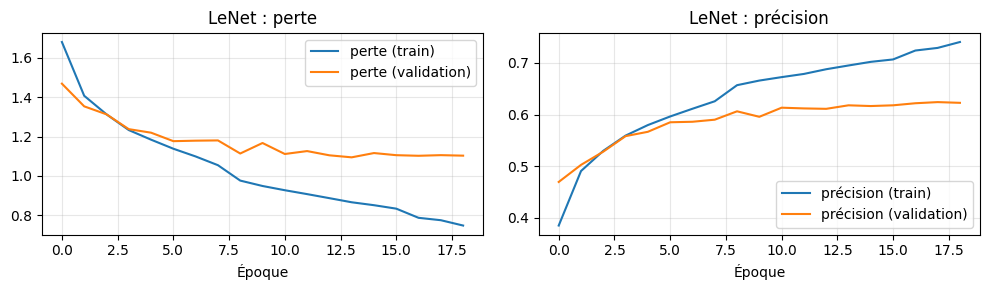

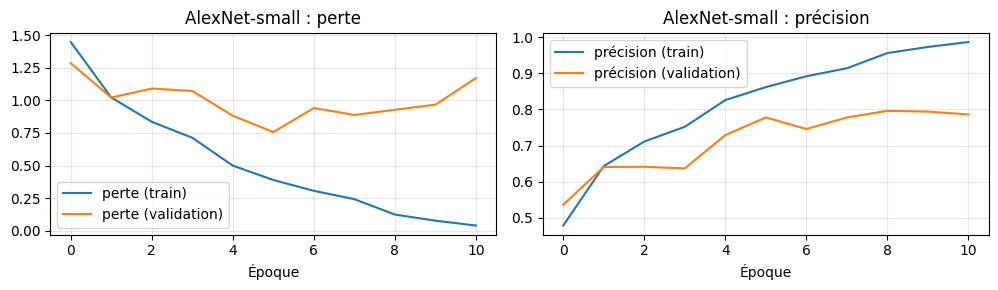

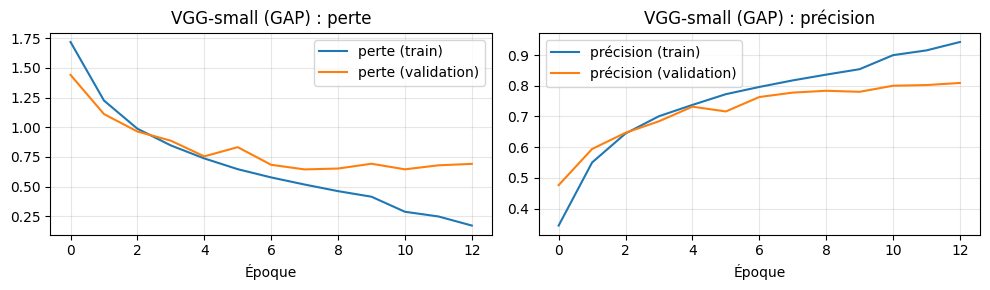

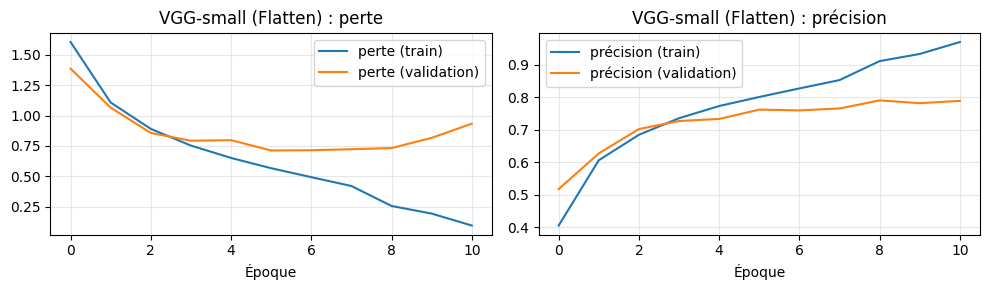

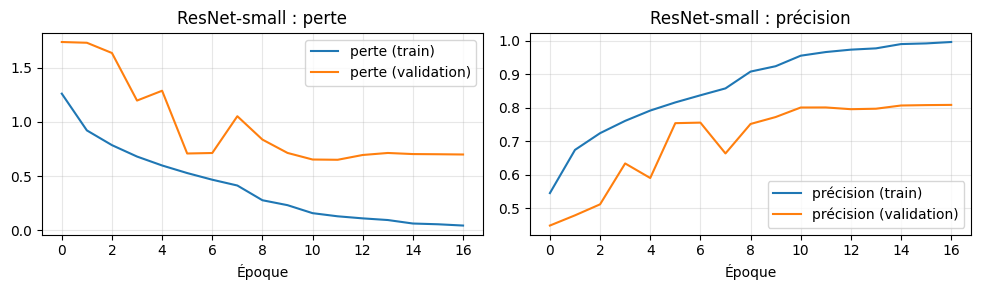

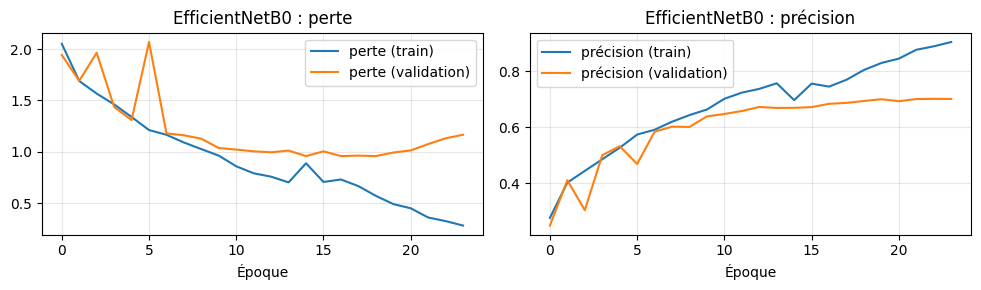

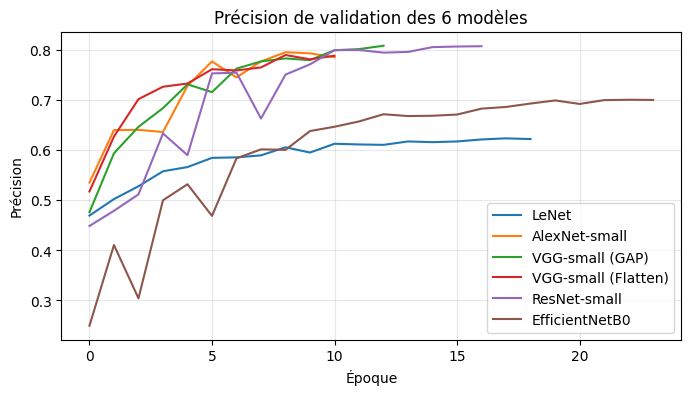

In [ ]:
import matplotlib.pyplot as plt

# Courbes de perte et de précision d'un modèle (entraînement contre validation)
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(history["loss"], label="perte (train)")
    axes[0].plot(history["val_loss"], label="perte (validation)")
    axes[0].set_title(title + " : perte")
    axes[1].plot(history["accuracy"], label="précision (train)")
    axes[1].plot(history["val_accuracy"], label="précision (validation)")
    axes[1].set_title(title + " : précision")
    for ax in axes:
        ax.set_xlabel("Époque")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Une figure par modèle
for nom, h in histories.items():
    plot_history(h, nom)

# Figure de comparaison : précision de validation des 6 modèles
plt.figure(figsize=(8, 4))
for nom, h in histories.items():
    plt.plot(h["val_accuracy"], label=nom)
plt.title("Précision de validation des 6 modèles")
plt.xlabel("Époque")
plt.ylabel("Précision")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Signaux à repérer sur les courbes

- **Sous-apprentissage :** les performances sont faibles sur les données d’entraînement et de validation.
- **Surapprentissage :** la performance sur l’entraînement continue de s’améliorer, tandis que la validation stagne ou se dégrade.
- **Instabilité :** la perte présente de fortes oscillations entre les époques.
- **Plateau :** les métriques deviennent presque constantes et ne progressent plus.

L’interprétation doit se baser sur les courbes observées et non sur le nom de l’architecture uniquement.

## B. Indicateurs de diagnostic

In [ ]:
# Indicateurs chiffrés pour le diagnostic de chaque modèle
lignes = []
for nom, h in histories.items():
    val_acc = np.array(h["val_accuracy"])
    best = int(np.argmin(h["val_loss"]))           # meilleure époque
    atteint = np.where(val_acc >= 0.70)[0]         # première époque à 70 % de validation
    lignes.append({
        "Modèle": nom,
        "Meilleure époque": best + 1,
        "Époques pour 70 % val.": int(atteint[0]) + 1 if len(atteint) else "jamais",
        "Train acc. max (%)": round(100 * max(h["accuracy"]), 1),
        "Val. acc. max (%)": round(100 * val_acc.max(), 1),
        "Écart train-val (points)": round(100 * (h["accuracy"][best] - h["val_accuracy"][best]), 1),
    })
pd.DataFrame(lignes)

,Modèle,Meilleure époque,Époques pour 70 % val.,Train acc. max (%),Val. acc. max (%),Écart train-val (points)
0,LeNet,14,jamais,74.0,62.4,7.7
1,AlexNet-small,6,5,98.7,79.6,8.4
2,VGG-small (GAP),8,5,94.3,80.9,4.0
3,VGG-small (Flatten),6,3,97.0,79.1,3.9
4,ResNet-small,12,6,99.6,80.8,16.5
5,EfficientNetB0,19,22,90.4,70.1,11.1


Questions d’analyse

**1. Quelle architecture converge le plus vite ?**

On peut repérer la convergence en observant à quelle époque la `val_loss` commence à se stabiliser et où la `val_accuracy` atteint un niveau élevé. Il faut comparer les courbes pour déterminer le modèle concerné.

**2. La meilleure `val_accuracy` correspond-elle à la meilleure `test accuracy` ?**

Pas nécessairement. Les données de validation et de test sont différentes. Un modèle peut obtenir la meilleure précision en validation sans obtenir la meilleure précision sur le test.

**3. Quel modèle montre l’écart train-validation le plus important ?**

Il faut comparer l’écart entre `accuracy` et `val_accuracy` pour chaque architecture. Un écart important peut indiquer un surapprentissage.

**4. Proposer une seule intervention pour le modèle le plus surajusté.**

Une intervention possible est d’augmenter le taux de `Dropout` dans la tête du modèle. Cette modification peut réduire le surapprentissage, mais son efficacité doit être vérifiée expérimentalement.

## C. Matrice de confusion du meilleur modèle

Meilleur modèle : ResNet-small
Epoch 1/30
704/704 - 22s - 31ms/step - accuracy: 0.5379 - loss: 1.2816 - val_accuracy: 0.4086 - val_loss: 1.8028 - learning_rate: 0.0010
Epoch 2/30
704/704 - 9s - 13ms/step - accuracy: 0.6710 - loss: 0.9332 - val_accuracy: 0.4836 - val_loss: 1.6198 - learning_rate: 0.0010
Epoch 3/30
704/704 - 9s - 13ms/step - accuracy: 0.7219 - loss: 0.7867 - val_accuracy: 0.6522 - val_loss: 1.0160 - learning_rate: 0.0010
Epoch 4/30
704/704 - 9s - 13ms/step - accuracy: 0.7592 - loss: 0.6817 - val_accuracy: 0.6918 - val_loss: 0.8851 - learning_rate: 0.0010
Epoch 5/30
704/704 - 9s - 13ms/step - accuracy: 0.7910 - loss: 0.6006 - val_accuracy: 0.7270 - val_loss: 0.8015 - learning_rate: 0.0010
Epoch 6/30
704/704 - 9s - 13ms/step - accuracy: 0.8188 - loss: 0.5254 - val_accuracy: 0.7664 - val_loss: 0.6870 - learning_rate: 0.0010
Epoch 7/30
704/704 - 9s - 13ms/step - accuracy: 0.8375 - loss: 0.4680 - val_accuracy: 0.7396 - val_loss: 0.8122 - learning_rate: 0.0010
Epoch 8/30
704/7

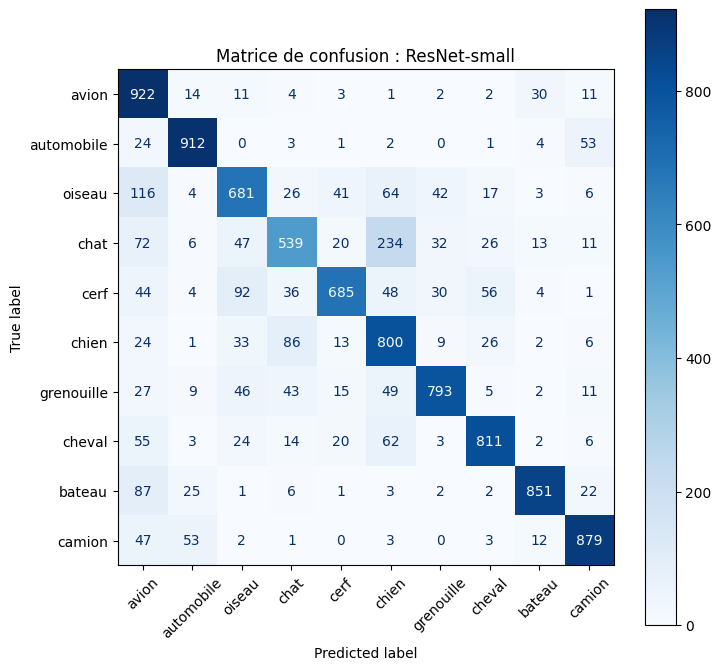

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Choix du meilleur modèle selon la précision de test
meilleur = tableau.sort_values("test_acc", ascending=False).iloc[0]["model"]
print("Meilleur modèle :", meilleur)

# Réentraînement avec les mêmes réglages
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model = model_builders[meilleur]()
compile_and_train(model, train_ds, val_ds)

# Prédictions sur le jeu de test et matrice de confusion
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("Matrice de confusion : " + meilleur)
plt.show()

## D. Ablation (Flatten contre GAP)





**Option C — Classifieur : Flatten vs GlobalAveragePooling**

- **Architecture :** VGG-small.
- **Configuration témoin :** tête de classification avec Flatten.
- **Configuration modifiée :** tête de classification avec GlobalAveragePooling2D.
- **Facteur étudié :** la méthode de réduction des caractéristiques avant la classification.
- **Hypothèse :** GlobalAveragePooling2D devrait réduire le nombre de paramètres de la tête de classification et pourrait limiter le surapprentissage. Son effet sur la précision doit être vérifié expérimentalement.

Pour garantir une comparaison équitable, les deux modèles utilisent les mêmes données, le même nombre maximal d’époques, le même optimiseur et les mêmes critères d’arrêt.



In [ ]:
# Ablation : Flatten (témoin) contre GlobalAveragePooling (modifiée) sur VGG-small
t = tableau.set_index("model")
a = t.loc["VGG-small (Flatten)"]
b = t.loc["VGG-small (GAP)"]

ablation = pd.DataFrame({
    "Mesure": ["Paramètres", "Val. accuracy (%)",
               "Temps / époque (s)", "Écart train-val (points)"],
    "Témoin (Flatten)": [a["params"], a["val_acc"], a["sec_per_epoch"], a["gap_train_val"]],
    "Modifiée (GAP)":   [b["params"], b["val_acc"], b["sec_per_epoch"], b["gap_train_val"]],
})
ablation["Écart"] = (ablation["Modifiée (GAP)"] - ablation["Témoin (Flatten)"]).round(2)
ablation

,Mesure,Témoin (Flatten),Modifiée (GAP),Écart
0,Paramètres,455082.00,435882.00,-19200.00
1,Val. accuracy (%),76.22,77.78,1.56
2,Temps / époque (s),6.90,7.40,0.50
3,Écart train-val (points),3.89,3.98,0.09


## Synthèse finale

Dans ce TP, nous avons comparé plusieurs architectures de réseaux de neurones convolutifs (CNN) sur le jeu de données CIFAR-10. Nous avons utilisé les mêmes conditions générales : un batch de 64 images, un maximum de 30 époques et un arrêt anticipé avec une patience de 5.

Les résultats montrent que **ResNet-small obtient la meilleure précision**, avec 80,13 % sur les données de test. Il est suivi par VGG-small GAP avec 78,43 %, puis AlexNet-small avec 77,43 %.

LeNet est le modèle le plus léger et le plus rapide à entraîner, mais sa précision est plus faible (62,80 %). EfficientNetB0 possède environ 4 millions de paramètres et demande plus de temps d'entraînement, sans obtenir une meilleure précision dans notre expérience.

Nous avons également comparé les deux versions de VGG-small. La version GAP utilise moins de paramètres que la version Flatten et obtient de meilleurs résultats dans notre expérience.

Pour notre projet, **VGG-small GAP représente un bon compromis** entre la précision, le nombre de paramètres et le temps d'entraînement. Cependant, ResNet-small reste le meilleur modèle selon la précision obtenue sur les données de test.

Cette étude présente quelques limites : chaque modèle n'a pas été testé plusieurs fois de manière systématique, aucune augmentation de données n'a été utilisée et EfficientNetB0 a été entraîné à partir de zéro sur de petites images de 32 × 32 pixels. Les résultats peuvent donc varier selon les conditions d'entraînement.

### Question de sortie : Quelle est l'innovation la plus importante ?

L'innovation importante de ResNet est la **connexion résiduelle (*skip connection*)**. Elle permet de transmettre plus facilement l'information à travers les différentes couches du réseau et facilite l'entraînement des réseaux profonds. Dans notre TP, ResNet-small a obtenu la meilleure précision sur les données de test.

## Partie D — Interpréter les compromis architecturaux

Chaque architecture CNN repose sur une idée différente. Le choix dépend de la précision recherchée, du temps de calcul, de la mémoire disponible et de la facilité de déploiement.

- **LeNet :** architecture courte, adaptée comme modèle de référence. Elle est simple, mais sa capacité peut être limitée.
- **AlexNet :** utilise notamment ReLU, le dropout et plusieurs couches pour apprendre des caractéristiques plus riches. Sa tête de classification peut être coûteuse.
- **VGG :** utilise des blocs réguliers de convolutions 3 × 3. Cette structure est simple à comprendre, mais peut nécessiter beaucoup de paramètres.
- **ResNet :** utilise des connexions résiduelles pour faciliter l’optimisation des réseaux profonds. Ses blocs ajoutent toutefois de la complexité.
- **EfficientNet :** repose sur le scaling composé et les blocs MBConv. Il vise une bonne efficacité, mais ses performances dépendent du contexte d’utilisation.

### 1. Quel modèle recommanderiez-vous pour un prototype rapide sur CPU ?

Je recommande **LeNet**, car il est léger, simple et rapide à entraîner.

### 2. Quel modèle choisir si la mémoire est limitée mais que l'accuracy reste prioritaire ?

Je choisirais **EfficientNetB0** comme candidat à tester, puis je vérifierais sa précision et sa consommation mémoire.

### 3. Pourquoi le nombre de paramètres ne suffit-il pas à prédire la latence ?

Parce que la latence dépend aussi des calculs, des couches du modèle, de la mémoire et du matériel utilisé.

### 4. Les résultats sur CIFAR-10 permettent-ils de conclure pour des images haute résolution ?

Non, car CIFAR-10 contient de petites images de 32 × 32 pixels. Il faut tester le modèle sur des images haute résolution.

### 5. Distinguer performance statistique, efficacité calculatoire et facilité de déploiement.

- **Performance statistique :** capacité du modèle à bien classer les images.
- **Efficacité calculatoire :** temps de calcul et ressources utilisées.
- **Facilité de déploiement :** facilité d'installation et d'utilisation du modèle sur le matériel cible.

Je recommande VGG-small GAP pour son bon compromis entre précision et nombre de paramètres. Cependant, ResNet-small obtient la meilleure précision de test dans notre expérience, avec 80,13 %.

Question de sortie

L'innovation la plus importante est la connexion résiduelle de ResNet, car elle facilite l'entraînement des réseaux profonds et améliore les résultats obtenus dans notre expérience.

## Auto-évaluation générale

J'ai compris les principales architectures CNN et leur fonctionnement général, notamment LeNet, AlexNet, VGG, ResNet et EfficientNet. Je comprends également les différences entre ces modèles et leurs avantages et limites.

Cependant, j'ai encore des difficultés dans la dernière partie du TP, surtout dans la partie C, où certains codes et certaines étapes restent difficiles à comprendre.

Je dois donc continuer à réviser les notions étudiées, à mieux relier la théorie à la pratique et à refaire les TP et les TD plusieurs fois. Mon objectif est de pouvoir comprendre le code, expliquer son rôle et réaliser les exercices de manière autonome, sans aide.